# 02 — Visão global do projeto Playgorithm

Este notebook demonstra os **seis elementos implementados**, desde a preparação dos dados até ao planeamento de vários jogos, incluindo a comparação **algoritmo genético (GA) × MDP** e a análise sem fadiga.

Complementa [01_data_overview.ipynb](01_data_overview.ipynb), dedicado às fontes originais. As tabelas e os gráficos abaixo são calculados a partir dos artefactos locais; não é necessário voltar a treinar modelos ou executar a otimização. Executar as células pela ordem apresentada, num ambiente com as dependências de `requirements.txt`.

| Elemento | Objetivo | Implementação |
|---|---|---|
| 1 | Preparar e auditar dados | `prepare_data.py` |
| 2 | Prever o vencedor | `train_results.py`, `predict_game.py` |
| 3 | Avaliar jogadores e quintetos | `train_performance.py`, `evaluate_lineup.py` |
| 4 | Escolher titulares e minutos | `plan_rotation.py` |
| 5 | Decidir substituições e comparar GA/MDP | `plan_substitutions.py`, `compare_genetic_substitutions.py`, `query_substitution.py` |
| 6 | Integrar decisões em vários jogos | `plan_horizon.py` |

Fluxo: dados → previsões de resultados e desempenho → rotação com restrições → substituições → plano de vários jogos.


In [ ]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts/prepare_data.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook dentro da pasta do projeto.')
REPORTS = ROOT / 'reports'
DATA = ROOT / 'data/processed'
pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def read_csv(path, **kwargs):
    # Preservar zeros iniciais nos identificadores dos jogos.
    return pd.read_csv(path, dtype={'game_id': 'string', 'player_id': 'string',
                                   'team_id': 'string'}, **kwargs)

folders = ['result_prediction', 'performance', 'rotation', 'substitutions',
           'genetic_substitutions', 'genetic_substitutions_no_fatigue', 'horizon']
status = pd.DataFrame([{'módulo': f, 'concluído': (REPORTS/f/'_SUCCESS').exists()}
                       for f in folders])
display(status)
assert status['concluído'].all(), 'Faltam experiências: consultar os comandos no final.'
print('Raiz do projeto:', ROOT)


,módulo,concluído
0,result_prediction,True
1,performance,True
2,rotation,True
3,substitutions,True
4,genetic_substitutions,True
5,genetic_substitutions_no_fatigue,True
6,horizon,True


Raiz do projeto: /home/domingos/Disciplinas_Meia/challenge-two


## 1. Preparação, cobertura e qualidade dos dados

As fontes foram normalizadas em tabelas de jogos, equipas, jogadores, eventos e lesões. As correções ficam em `repairs.csv`; registos rejeitados ficam em `quarantine.csv`. As estatísticas básicas e alargadas permanecem separadas.

O inventário usa o relatório de qualidade da preparação, evitando carregar milhões de eventos em memória. As contagens são as registadas nesse relatório, não uma nova auditoria integral dos CSV. [Metodologia](../docs/DATA_PREPARATION.md).


,tabela,linhas,colunas,valores_ausentes
0,event_key_conflicts,0,4,0
1,quarantine,5,4,0
2,repairs,115200,7,0
3,games,8283,26,66759
4,team_games,16566,60,176781
5,player_games,215473,42,968940
6,team_games_extended,16566,105,160215
7,player_games_extended,176614,112,777611
8,players,1193,22,1034
9,source_game_matches,8474,5,0


,game_id,game_date,season_start,hometeam_name,awayteam_name,home_score,away_score,split
0,0022501193,2026-04-12 20:30:00,2025,Mavericks,Bulls,149,128,test
1,0022501194,2026-04-12 20:30:00,2025,Rockets,Grizzlies,132,101,test
2,0022501195,2026-04-12 20:30:00,2025,Timberwolves,Pelicans,132,126,test
3,0022501196,2026-04-12 20:30:00,2025,Thunder,Suns,103,135,test
4,0022501197,2026-04-12 20:30:00,2025,Spurs,Nuggets,118,128,test


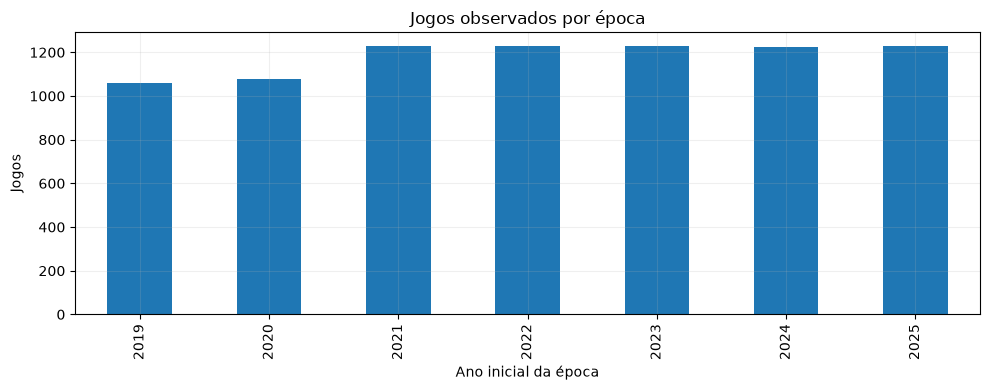

Relatório gerado em: 2026-11-21T20:09:29.255945+00:00


In [2]:
quality = read_json(DATA/'quality_report.json')
inventory = pd.DataFrame([
    {'tabela': name, 'linhas': info['rows'], 'colunas': len(info['columns']),
     'valores_ausentes': sum(info['missing'].values())}
    for name, info in quality['tables'].items()
])
print('Relatório gerado em:', quality['created_at_utc'])
display(inventory)
games = read_csv(DATA/'games.csv')
assert games['game_id'].is_unique
display(games[['game_id', 'game_date', 'season_start', 'hometeam_name',
               'awayteam_name', 'home_score', 'away_score', 'split']].head())
games.groupby('season_start').size().plot.bar(title='Jogos observados por época', ylabel='Jogos', xlabel='Ano inicial da época')
plt.tight_layout()
plt.show()


In [3]:
missing = pd.DataFrame([
    {'tabela': name, 'campo': field, 'ausentes': count,
     'percentagem': 100 * count / info['rows']}
    for name, info in quality['tables'].items() if info['rows']
    for field, count in info['missing'].items() if count
]).sort_values('percentagem', ascending=False)
display(missing.head(20))
display(read_csv(DATA/'quarantine.csv').drop(columns=['record_json'], errors='ignore'))
display(read_csv(DATA/'repairs.csv', nrows=5))
display(read_csv(DATA/'data_dictionary.csv', nrows=10))
print('Avisos registados na preparação:')
for warning in quality['warnings']:
    print('•', warning)


,tabela,campo,ausentes,percentagem
30,team_games,series_game_number,16566,100.0000
48,team_games_extended,series_game_number,16566,100.0000
26,team_games,coach_id,16566,100.0000
75,player_games_extended,comment,176614,100.0000
49,team_games_extended,seed,16530,99.7827
31,team_games,seed,16530,99.7827
109,play_by_play,subs_in_person_id,4595948,99.7409
100,injury_reports,category,1233613,99.5233
58,team_games_extended,ot2_points,16482,99.4929
35,team_games,ot2_points,16482,99.4929


,source_file,source_row,reason
0,kaggle_eoinamoore_historical_nba/Games.csv,1817,missing or invalid final score
1,kaggle_eoinamoore_historical_nba/Games.csv,1915,missing or invalid final score
2,kaggle_eoinamoore_historical_nba/Games.csv,2556,regular season label conflicts with game ID pr...
3,kaggle_eoinamoore_historical_nba/TeamStatistic...,1758,team not in game
4,kaggle_eoinamoore_historical_nba/TeamStatistic...,1759,team not in game


,source_file,source_row,game_id,player_id,field,value,rule
0,kaggle_eoinamoore_historical_nba/PlayerStatist...,10525,0022501179,203507,team_id,1610612749,home flag and both city/name pairs match game
1,kaggle_eoinamoore_historical_nba/PlayerStatist...,10525,0022501179,203507,opponent_team_id,1610612751,home flag and both city/name pairs match game
2,kaggle_eoinamoore_historical_nba/PlayerStatist...,10534,0022501179,1630533,team_id,1610612751,home flag and both city/name pairs match game
3,kaggle_eoinamoore_historical_nba/PlayerStatist...,10534,0022501179,1630533,opponent_team_id,1610612749,home flag and both city/name pairs match game
4,kaggle_eoinamoore_historical_nba/PlayerStatist...,10535,0022501179,1641730,team_id,1610612751,home flag and both city/name pairs match game


,table,column,storage,missing_values,note
0,event_key_conflicts,game_id,CSV text,0,Read as string. Game IDs have 10 digits; prese...
1,event_key_conflicts,period,CSV text,0,Normalized source column; see input manifest a...
2,event_key_conflicts,action_number,CSV text,0,Normalized source column; see input manifest a...
3,event_key_conflicts,source_record_count,CSV text,0,Normalized source column; see input manifest a...
4,quarantine,source_file,CSV text,0,Normalized source column; see input manifest a...
5,quarantine,source_row,CSV text,0,Normalized source column; see input manifest a...
6,quarantine,reason,CSV text,0,Normalized source column; see input manifest a...
7,quarantine,record_json,CSV text,0,Normalized source column; see input manifest a...
8,repairs,source_file,CSV text,0,Normalized source column; see input manifest a...
9,repairs,source_row,CSV text,0,Normalized source column; see input manifest a...


Avisos registados na preparação:
• Injury reports retain all publication times. Source timezone semantics are unverified. No pregame availability snapshot is supplied; confirm timezones and apply an as-of cutoff before prediction.
• Events are prepared, but five-player lineups are not reconstructed or certified. Source row preserves order; action numbers are not assumed unique. Check starters, substitutions, periods and event coverage before lineup analysis.
• event_key_conflicts.csv lists repeated game/period/action-number identities. Resolve source versions before counting events or reconstructing lineups; no arbitrary version is selected.
• Game timestamps retain the source value without an assumed timezone.
• Season coverage describes observed rows, not independently certified complete seasons.
• Basic and extended statistics remain separate. Join on documented keys with cardinality validation.
• Box scores and season totals contain postgame information. Shift histories before pred

A cobertura observada não certifica que todas as épocas estejam completas. Os horários de publicação das lesões não têm semântica temporal confirmada; por isso, não entram nas previsões pré-jogo. Os eventos preparados não equivalem a quintetos em campo reconstruídos e certificados.


## 2. Previsão do resultado dos jogos

O alvo é a probabilidade de vitória da equipa da casa. As variáveis usam apenas dias anteriores: médias recentes, estatísticas da época, descanso e Elo. Imputação e normalização são ajustadas no treino. A seleção usa **log loss de validação**; o teste fica reservado para a avaliação final.

Treino: 2019–20 a 2023–24; validação: 2024–25; teste: 2025–26. No teste, os pesos ficam fixos, mas o histórico incorpora resultados de dias anteriores. [Metodologia](../docs/RESULT_PREDICTION.md).


,games,first_date,last_date
train,5829,2019-10-22,2024-04-14
validation,1224,2024-10-22,2025-04-13
test,1230,2025-10-21,2026-04-12


,accuracy,log_loss,brier_score,roc_auc
logistic_C0.1,0.6773,0.6032,0.2085,0.7297
logistic_C1,0.6740,0.6038,0.2087,0.7291
logistic_C10,0.6732,0.6041,0.2089,0.7289
gradient_boosting_l2_10,0.6634,0.6123,0.2121,0.7196
random_forest,0.6601,0.6135,0.2128,0.7183
gradient_boosting_l2_1,0.6552,0.6180,0.2147,0.7116
elo,0.6520,0.6184,0.2152,0.7132
home_prior,0.5441,0.6894,0.2481,0.5000


,accuracy,log_loss,brier_score,roc_auc
logistic_C0.1,0.6715,0.6034,0.2081,0.7287
home_prior,0.5545,0.6872,0.2470,0.5000
elo,0.6780,0.6080,0.2096,0.7260


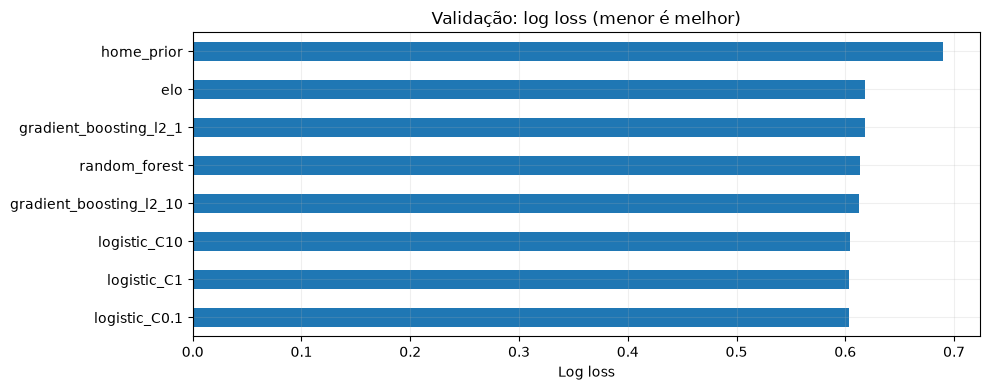

,feature,description,cutoff
0,diff_last5_win,"Home minus away mean win, using last 5 games i...",Earlier source calendar days only; no current-...
1,diff_last5_points_for,"Home minus away mean points_for, using last 5 ...",Earlier source calendar days only; no current-...
2,diff_last5_points_against,"Home minus away mean points_against, using las...",Earlier source calendar days only; no current-...
3,diff_last5_margin,"Home minus away mean margin, using last 5 game...",Earlier source calendar days only; no current-...
4,diff_last5_assists,"Home minus away mean assists, using last 5 gam...",Earlier source calendar days only; no current-...
5,diff_last5_rebounds,"Home minus away mean rebounds, using last 5 ga...",Earlier source calendar days only; no current-...
6,diff_last5_turnovers,"Home minus away mean turnovers, using last 5 g...",Earlier source calendar days only; no current-...
7,diff_last5_fg_percentage,"Home minus away mean fg_percentage, using last...",Earlier source calendar days only; no current-...
8,diff_last5_three_percentage,"Home minus away mean three_percentage, using l...",Earlier source calendar days only; no current-...
9,diff_last5_ft_percentage,"Home minus away mean ft_percentage, using last...",Earlier source calendar days only; no current-...


Modelo selecionado: logistic_C0.1
Verificado: datas de histórico exportadas anteriores ao dia previsto.


In [4]:
result = read_json(REPORTS/'result_prediction/metrics.json')
display(pd.DataFrame(result['splits']).T)
validation = pd.DataFrame(result['validation']).T.sort_values('log_loss')
test = pd.DataFrame(result['test']).T
print('Modelo selecionado:', result['selected_model'])
display(validation)
display(test)
validation['log_loss'].sort_values().plot.barh(title='Validação: log loss (menor é melhor)', xlabel='Log loss')
plt.tight_layout()
plt.show()
features = read_csv(REPORTS/'result_prediction/game_features.csv')
observed = features.dropna(subset=['latest_history_date'])
assert (pd.to_datetime(observed['latest_history_date']).dt.normalize() <
        pd.to_datetime(observed['game_date']).dt.normalize()).all()
print('Verificado: datas de histórico exportadas anteriores ao dia previsto.')
display(read_csv(REPORTS/'result_prediction/feature_dictionary.csv').head(10))


log_loss       0.6034
brier_score    0.2081
roc_auc        0.7287
accuracy       0.6715
Name: Teste recalculado, dtype: float64

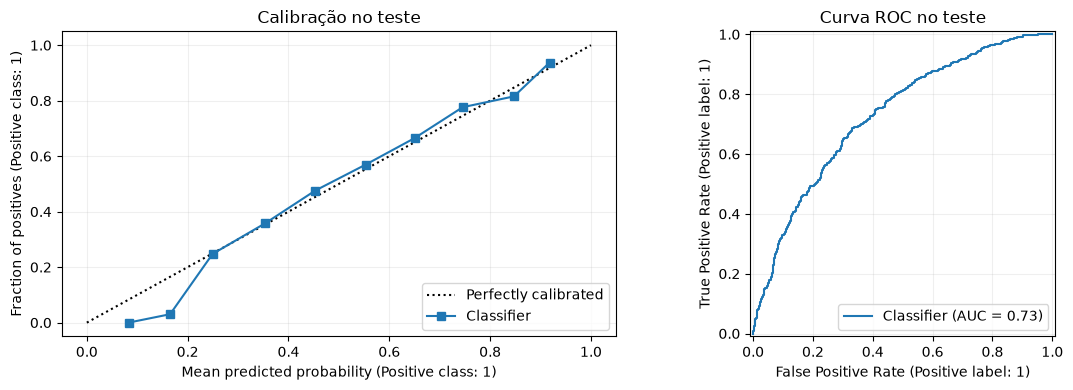

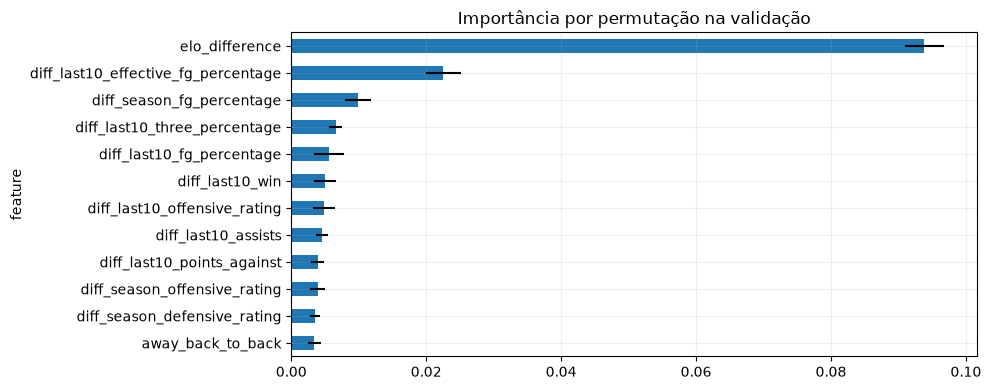

In [5]:
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, RocCurveDisplay
from sklearn.calibration import CalibrationDisplay
pred = read_csv(REPORTS/'result_prediction/test_predictions.csv')
y = pred['home_win']
p = pred['probability_' + result['selected_model']]
recomputed = {'log_loss': log_loss(y, p), 'brier_score': brier_score_loss(y, p),
              'roc_auc': roc_auc_score(y, p), 'accuracy': ((p >= 0.5) == y).mean()}
for metric, value in recomputed.items():
    assert np.isclose(value, result['test'][result['selected_model']][metric])
display(pd.Series(recomputed, name='Teste recalculado'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
CalibrationDisplay.from_predictions(y, p, n_bins=10, ax=axes[0])
RocCurveDisplay.from_predictions(y, p, ax=axes[1])
axes[0].set_title('Calibração no teste')
axes[1].set_title('Curva ROC no teste')
plt.tight_layout()
plt.show()
importance = read_csv(REPORTS/'result_prediction/validation_feature_importance.csv').head(12)
importance.sort_values('importance_mean').plot.barh(x='feature', y='importance_mean', xerr='importance_std', legend=False, title='Importância por permutação na validação')
plt.tight_layout()
plt.show()


Accuracy mede a proporção de classificações corretas; log loss e Brier avaliam probabilidades, com valores menores preferíveis; ROC-AUC mede discriminação. O modelo escolhido pode ter menor accuracy do que Elo e melhor log loss. A importância das variáveis não demonstra causalidade, sobretudo entre estatísticas correlacionadas.


## 3. Desempenho de jogadores e quintetos titulares

As previsões de pontos, ressaltos e assistências pressupõem participação e pelo menos cinco aparições anteriores na época. A referência é a média das últimas dez aparições. O modelo de quintetos estima associações com a margem final do jogo; não mede desempenho simultâneo em campo nem efeitos causais. Os titulares observados são retrospetivos. [Metodologia](../docs/PERFORMANCE_EVALUATION.md).


,Modelo: MAE,Últimos 10: MAE
points,4.6428,4.6715
rebounds_total,1.9315,1.9356
assists,1.3708,1.3756


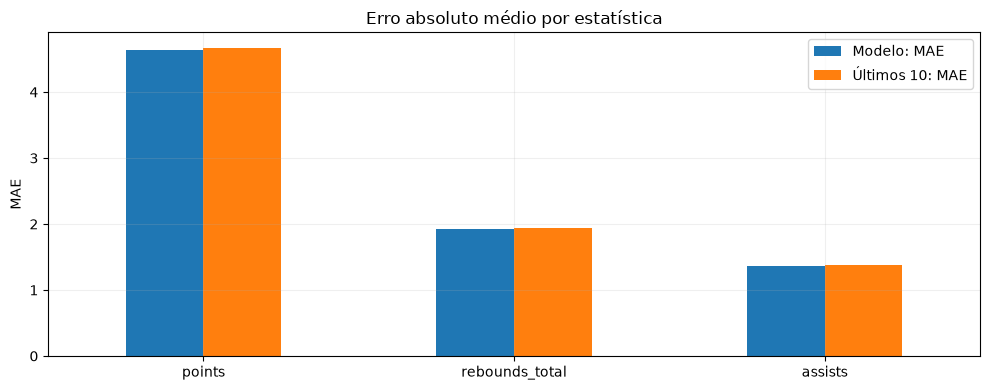

,modelo,referência
mae,12.1526,1.3106e+01
rmse,15.5029,1.6407e+01
r2,0.1071,-7.5891e-05


,season_start,games,accepted_lineup_games,excluded_lineup_games
0,2019,1059,1059,0
1,2020,1080,1080,0
2,2021,1230,1,1229
3,2022,1230,1230,0
4,2023,1230,1230,0
5,2024,1224,1224,0
6,2025,1230,1230,0


,game_id,player_id,name,game_date,team_id,points,rebounds_total,assists,...,points_baseline,points_residual,rebounds_total_predicted,rebounds_total_baseline,rebounds_total_residual,assists_predicted,assists_baseline,assists_residual
0,0022500138,1626145,Tyus Jones,2025-10-30,1610612753,5.0,0.0,0.0,...,1.8,1.3264,1.6744,1.2,-1.6744,1.8677,1.8,-1.8677
1,0022500138,1628976,Wendell Carter Jr.,2025-10-30,1610612753,18.0,8.0,3.0,...,9.0,8.7248,7.8577,8.2,0.1423,1.7325,1.4,1.2675
2,0022500138,1629048,Goga Bitadze,2025-10-30,1610612753,6.0,3.0,0.0,...,5.8,0.0731,6.1095,6.2,-3.1095,1.8743,2.0,-1.8743
3,0022500138,1630217,Desmond Bane,2025-10-30,1610612753,9.0,4.0,7.0,...,17.6,-9.4029,4.8370,4.8,-0.8370,3.1229,2.8,3.8771
4,0022500138,1630532,Franz Wagner,2025-10-30,1610612753,21.0,5.0,3.0,...,22.4,0.6084,5.6823,5.6,-0.6823,3.2919,3.0,-0.2919


,player_id,name,games,points,rebounds,assists,points_above_expectation,eligible_20_games
65,1628983,Shai Gilgeous-Alexander,63,30.8413,4.1429,6.6825,3.4829,True
529,203954,Joel Embiid,33,28.2424,8.0606,4.0606,3.3363,True
497,202695,Kawhi Leonard,60,28.2333,6.3833,3.6167,3.0402,True
236,1631105,Jalen Duren,65,19.8615,10.5692,2.0308,2.4661,True
500,202710,Jimmy Butler III,33,19.7879,5.6970,4.8788,2.4587,True
206,1630604,E.J. Liddell,21,6.4286,2.9524,1.1429,2.3104,True
254,1631131,Oscar Tshiebwe,22,8.8636,7.3636,1.2273,2.3046,True
533,203999,Nikola Jokic,60,28.2833,12.7333,10.7167,2.3043,True
127,1630162,Anthony Edwards,56,29.0714,5.0536,3.8214,2.2157,True
85,1629029,Luka Doncic,59,32.9322,7.4576,8.2034,2.1955,True


Modelo de jogadores: ridge_1
Tabela descritiva: pontos acima da previsão, entre jogadores com pelo menos 20 jogos.


In [6]:
performance = read_json(REPORTS/'performance/metrics.json')
player_metrics = pd.DataFrame({
    'Modelo: MAE': {k: v['mae'] for k,v in performance['players']['test'].items()},
    'Últimos 10: MAE': {k: v['mae'] for k,v in performance['players']['test_baseline'].items()}
})
print('Modelo de jogadores:', performance['players']['selected'])
display(player_metrics)
player_metrics.plot.bar(title='Erro absoluto médio por estatística', rot=0, ylabel='MAE')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'modelo': performance['starting_lineups']['test'],
                     'referência': performance['starting_lineups']['test_baseline']}))
display(read_csv(REPORTS/'performance/lineup_coverage.csv'))
display(read_csv(REPORTS/'performance/player_test_predictions.csv', nrows=5))
summary = read_csv(REPORTS/'performance/player_test_summary.csv')
display(summary[summary['eligible_20_games']].sort_values('points_above_expectation', ascending=False).head(10))
print('Tabela descritiva: pontos acima da previsão, entre jogadores com pelo menos 20 jogos.')


## 4. Quinteto inicial e distribuição de minutos

A programação por restrições combina prioridades previstas com disponibilidade, posições, limites de minutos e descanso. Cada bloco tem dois guards, dois forwards e um center; um jogo de 48 minutos soma 240 jogador-minutos. A utilidade é uma preferência de planeamento, não uma previsão de pontos ou vitórias. O cenário retrospetivo assume disponibilidade. [Metodologia](../docs/ROTATION_PLANNING.md).


,player_id,name,minutes,starter,utility,starter_association
0,1627759,Jaylen Brown,36,True,45.2299,1.8122
1,1628369,Jayson Tatum,36,True,37.3383,3.3061
2,1628401,Derrick White,36,True,26.9133,2.9694
3,1630573,Sam Hauser,28,True,12.5911,1.0659
4,202696,Nikola Vucevic,12,True,18.4120,0.8076
5,1629674,Neemias Queta,36,False,22.0131,0.1553
6,1630202,Payton Pritchard,36,False,28.5382,0.3507
7,1631248,Baylor Scheierman,20,False,16.1377,-0.1251
8,1629646,Charles Bassey,0,False,6.8041,-0.3801
9,1630568,Luka Garza,0,False,16.4789,0.0000


,block,quarter,start_minute,end_minute,G1,G2,F1,F2,C
0,0,1,0,4,Derrick White,Jayson Tatum,Jaylen Brown,Sam Hauser,Nikola Vucevic
1,1,1,4,8,Payton Pritchard,Derrick White,Jaylen Brown,Sam Hauser,Neemias Queta
2,2,1,8,12,Payton Pritchard,Derrick White,Jayson Tatum,Sam Hauser,Neemias Queta
3,3,2,12,16,Payton Pritchard,Baylor Scheierman,Jayson Tatum,Jaylen Brown,Neemias Queta
4,4,2,16,20,Derrick White,Baylor Scheierman,Jaylen Brown,Sam Hauser,Nikola Vucevic
5,5,2,20,24,Payton Pritchard,Baylor Scheierman,Jayson Tatum,Sam Hauser,Neemias Queta
6,6,3,24,28,Payton Pritchard,Derrick White,Jayson Tatum,Jaylen Brown,Neemias Queta
7,7,3,28,32,Payton Pritchard,Derrick White,Jayson Tatum,Jaylen Brown,Neemias Queta
8,8,3,32,36,Derrick White,Baylor Scheierman,Sam Hauser,Jaylen Brown,Nikola Vucevic
9,9,4,36,40,Baylor Scheierman,Payton Pritchard,Sam Hauser,Jayson Tatum,Neemias Queta


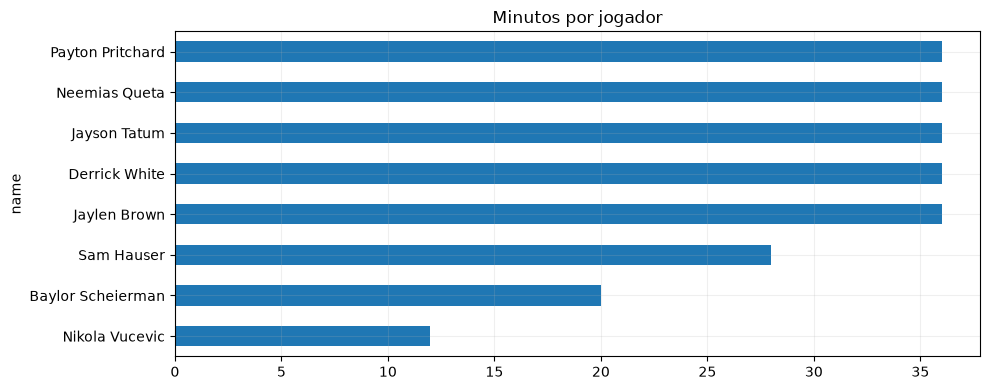

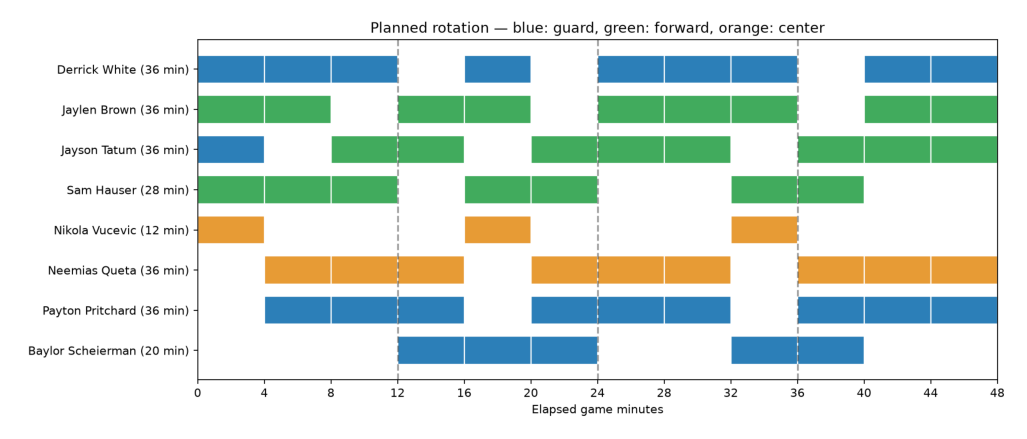

Estado: OPTIMAL | Objetivo: 148.655 | Limite: 148.655


In [7]:
rotation = read_json(REPORTS/'rotation/solution.json')
minutes = read_csv(REPORTS/'rotation/minutes.csv')
schedule = read_csv(REPORTS/'rotation/schedule.csv')
print('Estado:', rotation['status'], '| Objetivo:', rotation['objective'], '| Limite:', rotation['best_bound'])
display(minutes.sort_values(['starter', 'minutes'], ascending=False))
roles = ['G1', 'G2', 'F1', 'F2', 'C']
assert minutes['minutes'].sum() == 240
assert minutes['starter'].sum() == 5
assert schedule[roles].nunique(axis=1).eq(5).all()
assert (schedule['end_minute'] - schedule['start_minute']).sum() == 48
names = dict(zip(minutes['player_id'], minutes['name']))
display(schedule.assign(**{r: schedule[r].astype(str).map(names) for r in roles}))
minutes[minutes['minutes'] > 0].sort_values('minutes').plot.barh(x='name', y='minutes', legend=False, title='Minutos por jogador')
plt.tight_layout()
plt.show()
# Figura exportada pelo planeador.
plt.figure(figsize=(13, 6))
plt.imshow(plt.imread(REPORTS/'rotation/rotation.png'))
plt.axis('off')
plt.show()


## 5. Substituições: processo de decisão de Markov

O estado inclui bloco temporal, blocos restantes do período, permanência consecutiva dos jogadores, quinteto anterior e contexto (`balanced`, `playmaking`, `rebounding`). Cada ação escolhe um bloco existente; mantém os titulares e os minutos por jogador em cada período.

A recompensa combina produção prevista, contexto, penalização de fadiga e custo das substituições. A programação dinâmica calcula `V(s) = max_a [r(s,a) + Σ P(s′|s,a)V(s′)]`, com valor terminal zero. Transições e penalizações são hipóteses de simulação. [Metodologia](../docs/SUBSTITUTION_PLANNING.md).


In [8]:
mdp = read_json(REPORTS/'substitutions/metrics.json')
display(pd.Series(mdp['expected_utility'], name='Utilidade esperada exata'))
display(pd.DataFrame(mdp['transition'], index=['balanced','playmaking','rebounding'], columns=['balanced','playmaking','rebounding']))
display(pd.DataFrame(mdp['sensitivity']))
simulation = read_csv(REPORTS/'substitutions/simulation.csv')
display(simulation.groupby('policy').agg(episódios=('episode','count'), utilidade_média=('utility','mean'), desvio=('utility','std'), substituições=('substitutions','mean')))
# Consulta real da política exportada, sem voltar a otimizar.
if str(ROOT/'scripts') not in sys.path:
    sys.path.insert(0, str(ROOT/'scripts'))
from query_substitution import lookup
policy = read_json(REPORTS/'substitutions/policy.json')
initial = next(s for s in policy['states'] if s['block'] == 0 and s['context'] == 'balanced')
display(lookup(policy, initial))


mdp       131.7744
fixed     131.7744
greedy    131.7744
Name: Utilidade esperada exata, dtype: float64

,balanced,playmaking,rebounding
balanced,0.6,0.2,0.2
playmaking,0.2,0.6,0.2
rebounding,0.2,0.2,0.6


,persistence,fatigue,mdp,fixed
0,0.3,0.00,141.2048,141.1788
1,0.3,0.16,123.0274,123.0274
2,0.8,0.00,140.0283,140.0232
3,0.8,0.16,122.0152,122.0152


,episódios,utilidade_média,desvio,substituições
policy,,,,
fixed,500,131.6706,1.8258,21.0
greedy,500,131.6706,1.8258,21.0
mdp,500,131.6706,1.8258,21.0


{'source_block': 0, 'assignment': {'G1': '1628401', 'G2': '1628369', 'F1': '1627759', 'F2': '1630573', 'C': '202696'}, 'entering': [{'player_id': '1627759', 'name': 'Jaylen Brown'}, {'player_id': '1628369', 'name': 'Jayson Tatum'}, {'player_id': '1628401', 'name': 'Derrick White'}, {'player_id': '1630573', 'name': 'Sam Hauser'}, {'player_id': '202696', 'name': 'Nikola Vucevic'}], 'leaving': [], 'expected_remaining_utility': 131.7743815943359}

### 5.1. Algoritmo genético versus MDP

Cada gene escolhe uma ação legal num estado viável. A evolução usa seleção por torneio de três indivíduos, crossover uniforme, mutação e dois elites. A fitness é a utilidade esperada exata da política, sem usar decisões ótimas do MDP na evolução. O MDP fornece o limite superior para comparação posterior.

`runs.csv` contém uma linha por semente: `fitness` é a melhor utilidade, `seconds` é a duração dessa evolução e `unique_evaluations` conta cromossomas distintos avaliados. Os tempos excluem simulação, gráficos e exportação; não constituem um benchmark controlado. [Metodologia](../docs/GENETIC_SUBSTITUTIONS.md).


,seed,fitness,seconds,unique_evaluations
0,42,131.7744,0.0957,8
1,43,131.7744,0.1020,8
2,44,131.7744,0.1041,8
3,45,131.7744,0.0934,8
4,46,131.7744,0.0976,8


selected_seed          42.0
state_count            46.0
states_with_choice      3.0
population             40.0
generations            40.0
mutation                0.1
episodes              500.0
ga_gap_to_exact         0.0
dtype: float64

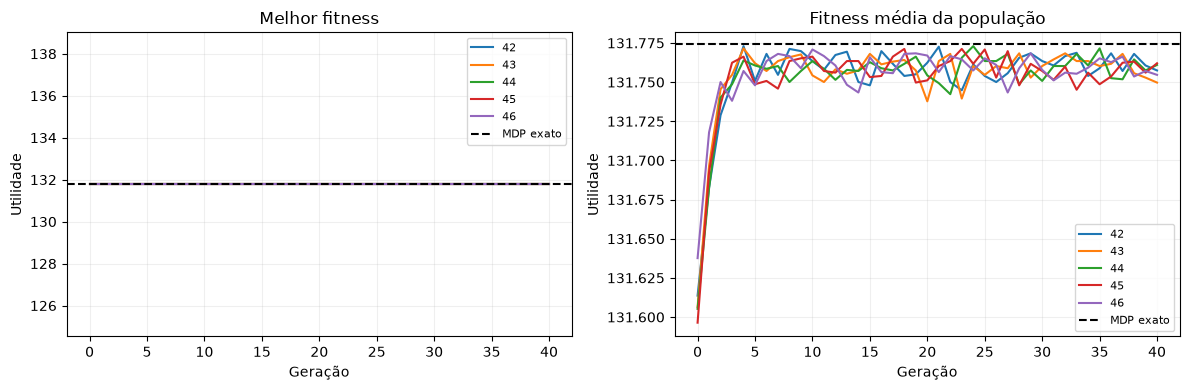

In [9]:
ga = read_json(REPORTS/'genetic_substitutions/metrics.json')
no_fatigue = read_json(REPORTS/'genetic_substitutions_no_fatigue/metrics.json')
runs = read_csv(REPORTS/'genetic_substitutions/runs.csv')
display(runs)
display(pd.Series({k: ga[k] for k in ['selected_seed', 'state_count', 'states_with_choice', 'population', 'generations', 'mutation', 'episodes', 'ga_gap_to_exact']}))
assert (runs['fitness'] <= ga['expected_utility']['mdp'] + 1e-9).all()
curves = read_csv(REPORTS/'genetic_substitutions/convergence.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed, group in curves.groupby('seed'):
    axes[0].plot(group['generation'], group['best'], label=str(seed))
    axes[1].plot(group['generation'], group['mean'], label=str(seed))
for ax, title in zip(axes, ['Melhor fitness', 'Fitness média da população']):
    ax.axhline(ga['expected_utility']['mdp'], color='black', linestyle='--', label='MDP exato')
    ax.set(xlabel='Geração', ylabel='Utilidade', title=title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [10]:
comparison = pd.DataFrame({'Fadiga base': ga['expected_utility'], 'Sem fadiga': no_fatigue['expected_utility']})
display(comparison)
paired_rows = []
for scenario, metrics in [('Fadiga base', ga), ('Sem fadiga', no_fatigue)]:
    for baseline, values in metrics['paired_comparisons'].items():
        low, high = values['monte_carlo_95_interval']
        paired_rows.append({'cenário': scenario, 'comparação': 'GA − '+baseline,
                            'diferença_média': values['mean_ga_minus_baseline'],
                            'IC95_inferior': low, 'IC95_superior': high})
display(pd.DataFrame(paired_rows))
for folder in ['genetic_substitutions', 'genetic_substitutions_no_fatigue']:
    sim = read_csv(REPORTS/folder/'simulation.csv')
    paired = sim.pivot(index='episode', columns='policy', values='utility')
    assert paired.notna().all().all()
    print(folder, '| trajetórias emparelhadas:', len(paired),
          '| média GA − fixed:', (paired['ga']-paired['fixed']).mean())


,Fadiga base,Sem fadiga
ga,131.7744,140.8419
mdp,131.7744,140.8419
fixed,131.7744,140.8298
greedy,131.7744,140.8298


,cenário,comparação,diferença_média,IC95_inferior,IC95_superior
0,Fadiga base,GA − mdp,0.0000,0.0000,0.0000
1,Fadiga base,GA − fixed,0.0000,0.0000,0.0000
2,Fadiga base,GA − greedy,0.0000,0.0000,0.0000
3,Sem fadiga,GA − mdp,0.0000,0.0000,0.0000
4,Sem fadiga,GA − fixed,0.0143,0.0103,0.0182
5,Sem fadiga,GA − greedy,0.0143,0.0103,0.0182


genetic_substitutions | trajetórias emparelhadas: 500 | média GA − fixed: 0.0
genetic_substitutions_no_fatigue | trajetórias emparelhadas: 500 | média GA − fixed: 0.01426263855694873


No cenário guardado, existem apenas **três estados com escolhas**, num total de 46, e oito cromossomas possíveis. As cinco execuções exploraram esses oito cromossomas; por isso, a melhor fitness pode ser constante desde a geração zero. A igualdade GA/MDP prova que se atingiu o limite deste modelo, sem demonstrar superioridade ou escalabilidade do GA.

Retirar a fadiga é uma análise de sensibilidade. As diferenças devem ser comparadas entre políticas dentro do mesmo cenário. Os intervalos emparelhados medem apenas erro de Monte Carlo, não incerteza sobre jogos reais.


## 6. Planeamento de vários jogos

O horizonte combina probabilidades de vitória, planos candidatos de minutos e políticas de substituição. A seleção respeita o orçamento total de cada jogador e limites para jogos em dias consecutivos. O estado ótimo refere-se à escolha entre candidatos gerados, não à otimização global de todas as rotações possíveis.

A distribuição de vitórias pressupõe resultados independentes. As rotações não alteram causalmente as probabilidades previstas. [Metodologia](../docs/HORIZON_PLANNING.md).


,game_id,game_date,home_team_id,away_team_id,season_start,win_probability,priority_weight,selected_cap,rotation_status,rotation_utility,mdp_expected_utility,fixed_expected_utility
0,0022501106,2026-04-01,1610612748,1610612738,2025,0.5949,1.9639,32,OPTIMAL,141.222,126.901,126.1062
1,0022501126,2026-04-03,1610612749,1610612738,2025,0.7842,1.6769,32,OPTIMAL,141.222,126.901,126.1062
2,0022501132,2026-04-05,1610612738,1610612761,2025,0.6825,1.8668,32,OPTIMAL,141.222,126.901,126.1062


,player_id,name,total_minutes
0,1627759,Jaylen Brown,96
1,1628369,Jayson Tatum,96
2,1628401,Derrick White,96
3,1629646,Charles Bassey,0
4,1629674,Neemias Queta,96
5,1630202,Payton Pritchard,96
6,1630568,Luka Garza,0
7,1630573,Sam Hauser,96
8,1631199,Ron Harper Jr.,0
9,1631248,Baylor Scheierman,96


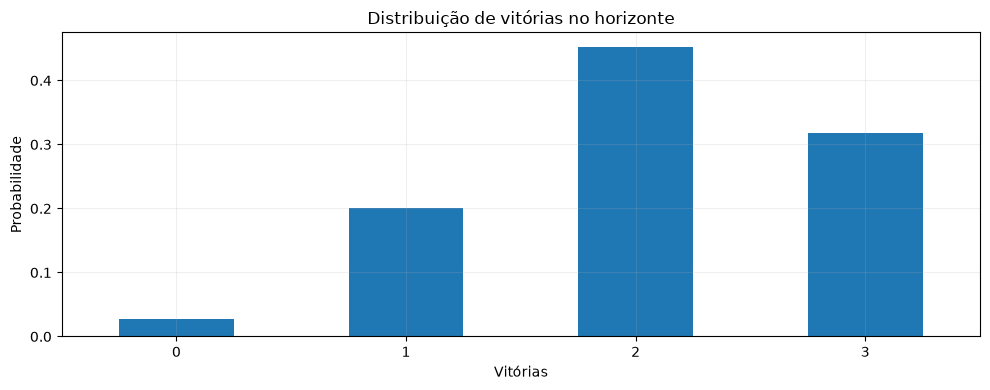

Objetivo: 2 vitórias em 3 jogos
Vitórias esperadas: 2.062
Probabilidade de atingir o objetivo: 77.1%


In [11]:
horizon = read_json(REPORTS/'horizon/metrics.json')
fixtures = read_csv(REPORTS/'horizon/games.csv')
totals = read_csv(REPORTS/'horizon/player_totals.csv')
distribution = read_csv(REPORTS/'horizon/win_distribution.csv')
display(fixtures)
display(totals)
assert (totals['total_minutes'] <= horizon['max_total_minutes']).all()
assert np.isclose(distribution['probability'].sum(), 1)
assert np.isclose(fixtures['win_probability'].sum(), horizon['expected_wins'])
# Recalcular a distribuição de vitórias sob independência.
probabilities = np.array([1.0])
for probability in fixtures['win_probability']:
    probabilities = np.convolve(probabilities, [1-probability, probability])
assert np.allclose(distribution.sort_values('wins')['probability'], probabilities)
assert np.isclose(probabilities[horizon['target_wins']:].sum(), horizon['probability_target'])
print(f"Objetivo: {horizon['target_wins']} vitórias em {len(fixtures)} jogos")
print(f"Vitórias esperadas: {horizon['expected_wins']:.3f}")
print(f"Probabilidade de atingir o objetivo: {horizon['probability_target']:.1%}")
distribution.plot.bar(x='wins', y='probability', legend=False, title='Distribuição de vitórias no horizonte', xlabel='Vitórias', ylabel='Probabilidade', rot=0)
plt.tight_layout()
plt.show()


## Reprodução e leitura dos resultados

Para **consultar** os resultados, basta executar este notebook. Para **regenerar** as experiências, executar os comandos seguintes na raiz do projeto, com o ambiente virtual ativado. Estes comandos escrevem os respetivos dados e relatórios; estão apresentados como documentação e não são executados pelo notebook.

```bash
python scripts/prepare_data.py
python scripts/train_results.py
python scripts/train_performance.py
python scripts/plan_rotation.py
python scripts/plan_substitutions.py
python scripts/compare_genetic_substitutions.py
python scripts/compare_genetic_substitutions.py --fatigue 0 --output-dir reports/genetic_substitutions_no_fatigue
python scripts/plan_horizon.py
python -m unittest discover -s tests
```

Consultar os guias de cada elemento para os argumentos e cenários. As sementes, configurações e hashes dos dados/modelos estão nos `metrics.json` e ficheiros de entradas. Alterações de dados ou versões podem alterar os resultados.

As verificações deste notebook confirmam consistência de métricas, datas e alguns totais; não substituem os testes dos planeadores ou a auditoria completa dos dados. O projeto demonstra previsão retrospetiva e otimização sob hipóteses explícitas. Não demonstra que uma rotação provoque mais vitórias, nem que as políticas simuladas sejam eficazes em jogos reais.
